# 04 — Validation Feature Ablation

## V2 research question

Do the 50-snapshot pre-submission history features improve validation performance beyond the static order, current LOB, and recent-flow variables available at `t0`?

This notebook compares the project brief's four nested feature sets across 5-, 30-, and 60-second horizons. It fits models on the supplied training period and evaluates them on the supplied validation period. The test rows and test outcomes remain sealed.

### Interpretation boundary

- These are preliminary, uncalibrated validation results.
- Model settings are fixed across feature sets to make the ablation comparable.
- Validation results may guide the next calibration and tuning stage, but they are not final test results.

In [1]:
from pathlib import Path
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

RANDOM_SEED = 42
HORIZONS = (5, 30, 60)

project_root_override = os.environ.get("LIMIT_ORDER_PROJECT_ROOT")
PROJECT_ROOT = Path(project_root_override) if project_root_override else Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from history_features import (
    AUDIT_ONLY_FEATURES,
    MODEL_HISTORY_FEATURES,
    add_order_side_features,
    build_history_features,
)

warnings.filterwarnings("ignore", category=FutureWarning)

excel_files = sorted(RAW_DIR.glob("*.xlsx"))
json_files = sorted(list(RAW_DIR.glob("*.json")) + list(RAW_DIR.glob("*.json.gz")))
assert len(excel_files) == 1
assert len(json_files) == 1

EXCEL_PATH = excel_files[0]
JSON_PATH = json_files[0]

print("Project root:", PROJECT_ROOT)
print("Random seed:", RANDOM_SEED)
print("History predictors:", len(MODEL_HISTORY_FEATURES))
print("Audit-only history fields:", AUDIT_ONLY_FEATURES)

Project root: <repository-root>
Random seed: 42
History predictors: 29
Audit-only history fields: ['last_event_to_submission_ms']


## Feature sets

- **A — Studied order:** side, time context, age, size, price distance, previous fills, and queue state.
- **B — Order + LOB at t0:** A plus the five-level book and compact LOB-state variables.
- **C — Order + LOB + recent flow:** B plus submissions, cancellations, modifications, aggressive trades, trade count, recency, and activity regime.
- **D — Full model with history:** C plus the 29 non-constant historical predictors validated in notebook 03.

`trade_intensity_per_s` and `same_side_cancel_intensity_per_s` are excluded because they are exact rescalings of count variables already in set C. Raw top-level imbalance is converted to order-side orientation before modeling.

In [2]:
A_NUMERIC = [
    "seconds_from_open",
    "order_age_s",
    "order_size",
    "price_distance_ticks",
    "quantity_filled_before_t0",
    "queue_ahead_qty",
    "same_price_total_qty",
    "normalized_queue_ahead",
]
A_CATEGORICAL = ["side", "session_phase"]

LOB_LEVEL_COLUMNS = []
for level in range(1, 6):
    LOB_LEVEL_COLUMNS.extend([
        f"bid_price_l{level}",
        f"bid_volume_l{level}",
        f"ask_price_l{level}",
        f"ask_volume_l{level}",
    ])

B_ADDITIONAL_NUMERIC = LOB_LEVEL_COLUMNS + [
    "mid_price",
    "spread_ticks",
    "relative_spread_bps",
    "oriented_top_level_imbalance",
    "five_level_side_imbalance",
    "same_side_depth_5",
    "opposite_side_depth_5",
    "microprice",
    "volatility_60s_bps",
]

C_ADDITIONAL_NUMERIC = [
    "same_side_submissions_10s",
    "opposite_side_submissions_10s",
    "same_side_cancellations_10s",
    "opposite_side_cancellations_10s",
    "modifications_10s",
    "aggressive_trade_volume_against_order_10s",
    "aggressive_trade_volume_with_order_side_10s",
    "trade_count_10s",
    "time_since_last_trade_ms",
]
C_ADDITIONAL_CATEGORICAL = ["market_activity_group"]

FEATURE_SETS = {
    "A_order": A_NUMERIC + A_CATEGORICAL,
    "B_order_lob": (
        A_NUMERIC + A_CATEGORICAL + B_ADDITIONAL_NUMERIC
    ),
    "C_order_lob_flow": (
        A_NUMERIC
        + A_CATEGORICAL
        + B_ADDITIONAL_NUMERIC
        + C_ADDITIONAL_NUMERIC
        + C_ADDITIONAL_CATEGORICAL
    ),
    "D_full_history": (
        A_NUMERIC
        + A_CATEGORICAL
        + B_ADDITIONAL_NUMERIC
        + C_ADDITIONAL_NUMERIC
        + C_ADDITIONAL_CATEGORICAL
        + MODEL_HISTORY_FEATURES
    ),
}

CATEGORICAL_FEATURES = set(A_CATEGORICAL + C_ADDITIONAL_CATEGORICAL)

for name, features in FEATURE_SETS.items():
    assert len(features) == len(set(features)), f"Duplicate feature in {name}"

feature_set_summary = pd.DataFrame([
    {
        "feature_set": name,
        "feature_count": len(features),
        "categorical_count": sum(feature in CATEGORICAL_FEATURES for feature in features),
        "numeric_count": sum(feature not in CATEGORICAL_FEATURES for feature in features),
    }
    for name, features in FEATURE_SETS.items()
])
feature_set_summary

,feature_set,feature_count,categorical_count,numeric_count
0,A_order,10,2,8
1,B_order_lob,39,2,37
2,C_order_lob_flow,49,3,46
3,D_full_history,78,3,75


In [3]:
orders = pd.read_excel(EXCEL_PATH, sheet_name="Orders")
assert len(orders) == 10_000
assert orders["order_id"].is_unique

split_normalized = orders["data_split"].astype(str).str.lower()
test_reservation = orders.loc[
    split_normalized.eq("test"),
    ["order_id", "data_split"],
].copy()
development_orders = orders.loc[
    split_normalized.isin(["train", "validation"])
].copy()
del orders

assert len(development_orders) == 8_500
assert len(test_reservation) == 1_500

started = time.perf_counter()
history_features = build_history_features(JSON_PATH)
history_seconds = time.perf_counter() - started

check_columns = [
    column for column in history_features.columns
    if column.startswith("check_")
]
assert len(history_features) == 10_000
assert history_features["order_id"].is_unique
assert history_features["history_snapshot_count"].eq(50).all()
assert history_features[check_columns].all().all()

# Cross-check the reusable module against the first row recorded in notebook 03.
first_history = history_features.iloc[0]
assert first_history["order_id"] == "ORD000001"
assert np.isclose(first_history["mid_return_1_50_bps"], -4.879239, atol=1e-6)
assert first_history["best_bid_change_count"] == 13
assert first_history["best_ask_change_count"] == 17

development = development_orders.merge(
    history_features,
    on="order_id",
    how="left",
    validate="one_to_one",
)
development = add_order_side_features(development)

buy_mask = development["side"].astype(str).str.lower().eq("buy")
development["oriented_top_level_imbalance"] = np.where(
    buy_mask,
    development["top_level_imbalance"],
    -development["top_level_imbalance"],
)

all_model_features = sorted(set(FEATURE_SETS["D_full_history"]))
assert set(all_model_features).issubset(development.columns)
assert development[all_model_features].notna().all().all()

print("Development rows:", len(development))
print("Reserved test rows:", len(test_reservation))
print("History build seconds:", round(history_seconds, 2))
print("Test target columns retained:", 0)

Development rows: 8500
Reserved test rows: 1500
History build seconds: 7.06
Test target columns retained: 0


In [4]:
balance_rows = []
for horizon in HORIZONS:
    eligibility = f"eligible_{horizon}s"
    target = f"target_fill_{horizon}s"
    for split_name in ("train", "validation"):
        mask = (
            development["data_split"].astype(str).str.lower().eq(split_name)
            & development[eligibility].eq(1)
        )
        y = development.loc[mask, target]
        assert y.notna().all()
        balance_rows.append({
            "horizon_seconds": horizon,
            "split": split_name,
            "eligible_rows": len(y),
            "fill_rate": y.mean(),
        })

class_balance = pd.DataFrame(balance_rows)
class_balance.assign(fill_rate_pct=100 * class_balance["fill_rate"]).round(2)

,horizon_seconds,split,eligible_rows,fill_rate,fill_rate_pct
0,5,train,6807,0.10,10.45
1,5,validation,1455,0.10,10.24
2,30,train,6173,0.42,41.81
3,30,validation,1324,0.40,39.58
4,60,train,5777,0.63,63.30
5,60,validation,1241,0.61,61.40


## Fixed model settings

The ablation uses one transparent linear model, one small rule-based tree, and one nonlinear forest. Hyperparameters are intentionally fixed in this notebook. This keeps changes in validation performance attributable to the information set rather than separate tuning decisions.

All preprocessing is inside each fitted pipeline, so imputers, scaling, and categorical encoding are learned from training rows only.

In [5]:
def build_preprocessor(features):
    categorical = [feature for feature in features if feature in CATEGORICAL_FEATURES]
    numeric = [feature for feature in features if feature not in CATEGORICAL_FEATURES]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric),
        ("categorical", categorical_pipeline, categorical),
    ], remainder="drop", sparse_threshold=0)


def model_factories():
    return {
        "logistic_regression": lambda: LogisticRegression(
            C=1.0,
            max_iter=3000,
            solver="lbfgs",
            random_state=RANDOM_SEED,
        ),
        "decision_tree": lambda: DecisionTreeClassifier(
            max_depth=4,
            min_samples_leaf=50,
            random_state=RANDOM_SEED,
        ),
        "random_forest": lambda: RandomForestClassifier(
            n_estimators=250,
            min_samples_leaf=5,
            max_features="sqrt",
            n_jobs=-1,
            random_state=RANDOM_SEED,
        ),
    }


def probability_metrics(y_true, probabilities, threshold=0.5):
    predictions = (probabilities >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(y_true, probabilities),
        "pr_auc": average_precision_score(y_true, probabilities),
        "brier_score": brier_score_loss(y_true, probabilities),
        "accuracy_at_0_5": accuracy_score(y_true, predictions),
        "precision_at_0_5": precision_score(y_true, predictions, zero_division=0),
        "recall_at_0_5": recall_score(y_true, predictions, zero_division=0),
        "f1_at_0_5": f1_score(y_true, predictions, zero_division=0),
    }

In [6]:
result_rows = []
validation_predictions = {}
training_started = time.perf_counter()

for horizon in HORIZONS:
    eligibility = f"eligible_{horizon}s"
    target = f"target_fill_{horizon}s"

    train_mask = (
        development["data_split"].astype(str).str.lower().eq("train")
        & development[eligibility].eq(1)
    )
    validation_mask = (
        development["data_split"].astype(str).str.lower().eq("validation")
        & development[eligibility].eq(1)
    )

    train_h = development.loc[train_mask]
    validation_h = development.loc[validation_mask]
    y_train = train_h[target].astype(int).to_numpy()
    y_validation = validation_h[target].astype(int).to_numpy()

    baseline_probability = float(y_train.mean())
    baseline_probabilities = np.full(len(y_validation), baseline_probability)
    result_rows.append({
        "horizon_seconds": horizon,
        "feature_set": "baseline",
        "feature_count": 0,
        "model": "empirical_fill_rate",
        **probability_metrics(y_validation, baseline_probabilities),
    })

    for feature_set_name, features in FEATURE_SETS.items():
        X_train = train_h[features]
        X_validation = validation_h[features]

        for model_name, factory in model_factories().items():
            pipeline = Pipeline([
                ("preprocessing", build_preprocessor(features)),
                ("model", factory()),
            ])
            pipeline.fit(X_train, y_train)
            probabilities = pipeline.predict_proba(X_validation)[:, 1]

            result_rows.append({
                "horizon_seconds": horizon,
                "feature_set": feature_set_name,
                "feature_count": len(features),
                "model": model_name,
                **probability_metrics(y_validation, probabilities),
            })
            validation_predictions[(horizon, feature_set_name, model_name)] = {
                "order_id": validation_h["order_id"].to_numpy(),
                "y_true": y_validation.copy(),
                "probability": probabilities.copy(),
            }

training_seconds = time.perf_counter() - training_started
validation_results = pd.DataFrame(result_rows)

print("Models fitted:", len(validation_results) - len(HORIZONS))
print("Total training seconds:", round(training_seconds, 2))
print("Test predictions produced:", 0)

Models fitted: 36
Total training seconds: 8.32
Test predictions produced: 0


In [7]:
metric_columns = [
    "roc_auc",
    "pr_auc",
    "brier_score",
    "accuracy_at_0_5",
    "precision_at_0_5",
    "recall_at_0_5",
    "f1_at_0_5",
]

ordered_results = validation_results.sort_values(
    ["horizon_seconds", "feature_set", "model"]
).reset_index(drop=True)

ordered_results[
    ["horizon_seconds", "feature_set", "model", "feature_count"] + metric_columns
].round(4)

,horizon_seconds,feature_set,model,feature_count,roc_auc,pr_auc,brier_score,accuracy_at_0_5,precision_at_0_5,recall_at_0_5,f1_at_0_5
0,5,A_order,decision_tree,10,0.6333,0.1698,0.0886,0.8976,0.0000,0.0000,0.0000
1,5,A_order,logistic_regression,10,0.6751,0.2377,0.0879,0.8976,0.0000,0.0000,0.0000
2,5,A_order,random_forest,10,0.6329,0.2222,0.0887,0.8990,1.0000,0.0134,0.0265
3,5,B_order_lob,decision_tree,39,0.6303,0.1853,0.0879,0.8976,0.0000,0.0000,0.0000
4,5,B_order_lob,logistic_regression,39,0.6645,0.2479,0.0873,0.8976,0.0000,0.0000,0.0000
5,5,B_order_lob,random_forest,39,0.6365,0.2326,0.0937,0.8976,0.0000,0.0000,0.0000
6,5,C_order_lob_flow,decision_tree,49,0.6187,0.1922,0.0877,0.8976,0.5000,0.0268,0.0510
7,5,C_order_lob_flow,logistic_regression,49,0.6679,0.2322,0.0877,0.8976,0.0000,0.0000,0.0000
8,5,C_order_lob_flow,random_forest,49,0.6331,0.2352,0.0941,0.8976,0.0000,0.0000,0.0000
9,5,D_full_history,decision_tree,78,0.5925,0.1644,0.0893,0.8976,0.5000,0.0268,0.0510


## Feature-set comparison

PR-AUC is the main comparison for the 5-second task because fills are rare. ROC-AUC and Brier score remain important at every horizon. Threshold metrics below use 0.5 only as a provisional reference; the classification threshold has not been selected yet.

In [8]:
pr_auc_table = (
    validation_results.loc[validation_results["feature_set"].ne("baseline")]
    .pivot_table(
        index=["horizon_seconds", "model"],
        columns="feature_set",
        values="pr_auc",
    )
    .reindex(columns=list(FEATURE_SETS))
)
pr_auc_table.round(4)

feature_set                          A_order  B_order_lob  C_order_lob_flow  \
horizon_seconds model                                                         
5               decision_tree         0.1698       0.1853            0.1922   
                logistic_regression   0.2377       0.2479            0.2322   
                random_forest         0.2222       0.2326            0.2352   
30              decision_tree         0.5343       0.5354            0.5400   
                logistic_regression   0.5833       0.5993            0.5993   
                random_forest         0.5759       0.5710            0.5926   
60              decision_tree         0.7153       0.7294            0.7217   
                logistic_regression   0.7671       0.7824            0.7864   
                random_forest         0.7666       0.7729            0.7891   

feature_set                          D_full_history  
horizon_seconds model                                
5               decision_tree                0.1644  
                logistic_regression          0.1984  
                random_forest                0.2160  
30              decision_tree                0.5400  
                logistic_regression          0.5927  
                random_forest                0.5976  
60              decision_tree                0.7256  
                logistic_regression          0.7792  
                random_forest                0.7873

In [9]:
comparison_keys = ["horizon_seconds", "model"]
c_results = validation_results.loc[
    validation_results["feature_set"].eq("C_order_lob_flow")
].set_index(comparison_keys)
d_results = validation_results.loc[
    validation_results["feature_set"].eq("D_full_history")
].set_index(comparison_keys)

history_delta = pd.DataFrame({
    "delta_pr_auc_D_minus_C": d_results["pr_auc"] - c_results["pr_auc"],
    "delta_roc_auc_D_minus_C": d_results["roc_auc"] - c_results["roc_auc"],
    "brier_improvement_C_minus_D": c_results["brier_score"] - d_results["brier_score"],
}).reset_index()

history_delta.round(4)

,horizon_seconds,model,delta_pr_auc_D_minus_C,delta_roc_auc_D_minus_C,brier_improvement_C_minus_D
0,5,logistic_regression,-0.0338,-0.0194,-0.0016
1,5,decision_tree,-0.0278,-0.0262,-0.0016
2,5,random_forest,-0.0192,-0.0177,0.0004
3,30,logistic_regression,-0.0066,-0.0073,-0.0019
4,30,decision_tree,0.0000,0.0000,0.0000
5,30,random_forest,0.0050,0.0062,-0.0005
6,60,logistic_regression,-0.0072,-0.0079,-0.0017
7,60,decision_tree,0.0039,0.0008,0.0005
8,60,random_forest,-0.0018,0.0030,-0.0007


### Paired uncertainty check

The C and D predictions cover the same validation orders, so the notebook uses 500 paired bootstrap resamples to estimate 95% intervals for their metric differences. Intervals spanning zero indicate that the observed history effect is not clearly distinguishable from validation-sample variation.

In [10]:
bootstrap_rows = []
model_names = list(model_factories())

for horizon in HORIZONS:
    for model_index, model_name in enumerate(model_names):
        c_prediction = validation_predictions[
            (horizon, "C_order_lob_flow", model_name)
        ]
        d_prediction = validation_predictions[
            (horizon, "D_full_history", model_name)
        ]

        assert np.array_equal(c_prediction["order_id"], d_prediction["order_id"])
        assert np.array_equal(c_prediction["y_true"], d_prediction["y_true"])

        y_true = c_prediction["y_true"]
        probability_c = c_prediction["probability"]
        probability_d = d_prediction["probability"]
        sample_size = len(y_true)
        rng = np.random.default_rng(RANDOM_SEED + horizon * 10 + model_index)

        bootstrap_deltas = []
        for _ in range(500):
            sample = rng.integers(0, sample_size, sample_size)
            y_sample = y_true[sample]
            if np.unique(y_sample).size < 2:
                continue
            bootstrap_deltas.append({
                "pr_auc": (
                    average_precision_score(y_sample, probability_d[sample])
                    - average_precision_score(y_sample, probability_c[sample])
                ),
                "roc_auc": (
                    roc_auc_score(y_sample, probability_d[sample])
                    - roc_auc_score(y_sample, probability_c[sample])
                ),
                "brier_improvement": (
                    brier_score_loss(y_sample, probability_c[sample])
                    - brier_score_loss(y_sample, probability_d[sample])
                ),
            })

        bootstrap_frame = pd.DataFrame(bootstrap_deltas)
        point = history_delta.loc[
            history_delta["horizon_seconds"].eq(horizon)
            & history_delta["model"].eq(model_name)
        ].iloc[0]

        bootstrap_rows.append({
            "horizon_seconds": horizon,
            "model": model_name,
            "delta_pr_auc_D_minus_C": point["delta_pr_auc_D_minus_C"],
            "pr_auc_ci_low": bootstrap_frame["pr_auc"].quantile(0.025),
            "pr_auc_ci_high": bootstrap_frame["pr_auc"].quantile(0.975),
            "delta_roc_auc_D_minus_C": point["delta_roc_auc_D_minus_C"],
            "roc_auc_ci_low": bootstrap_frame["roc_auc"].quantile(0.025),
            "roc_auc_ci_high": bootstrap_frame["roc_auc"].quantile(0.975),
            "brier_improvement_C_minus_D": point["brier_improvement_C_minus_D"],
            "brier_ci_low": bootstrap_frame["brier_improvement"].quantile(0.025),
            "brier_ci_high": bootstrap_frame["brier_improvement"].quantile(0.975),
        })

bootstrap_history_delta = pd.DataFrame(bootstrap_rows)
bootstrap_history_delta.round(4)

,horizon_seconds,model,delta_pr_auc_D_minus_C,pr_auc_ci_low,pr_auc_ci_high,delta_roc_auc_D_minus_C,roc_auc_ci_low,roc_auc_ci_high,brier_improvement_C_minus_D,brier_ci_low,brier_ci_high
0,5,logistic_regression,-0.0338,-0.0583,-0.0136,-0.0194,-0.0337,-0.0058,-0.0016,-0.0022,-0.0008
1,5,decision_tree,-0.0278,-0.0609,0.0016,-0.0262,-0.0549,-0.0013,-0.0016,-0.0034,-0.0001
2,5,random_forest,-0.0192,-0.0467,0.0094,-0.0177,-0.0474,0.0117,0.0004,-0.0006,0.0013
3,30,logistic_regression,-0.0066,-0.0121,0.0005,-0.0073,-0.0120,-0.0018,-0.0019,-0.0030,-0.0006
4,30,decision_tree,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
5,30,random_forest,0.0050,-0.0101,0.0180,0.0062,-0.0078,0.0200,-0.0005,-0.0026,0.0016
6,60,logistic_regression,-0.0072,-0.0116,-0.0021,-0.0079,-0.0135,-0.0016,-0.0017,-0.0029,-0.0003
7,60,decision_tree,0.0039,-0.0015,0.0108,0.0008,-0.0005,0.0026,0.0005,-0.0001,0.0013
8,60,random_forest,-0.0018,-0.0115,0.0088,0.0030,-0.0090,0.0155,-0.0007,-0.0024,0.0013


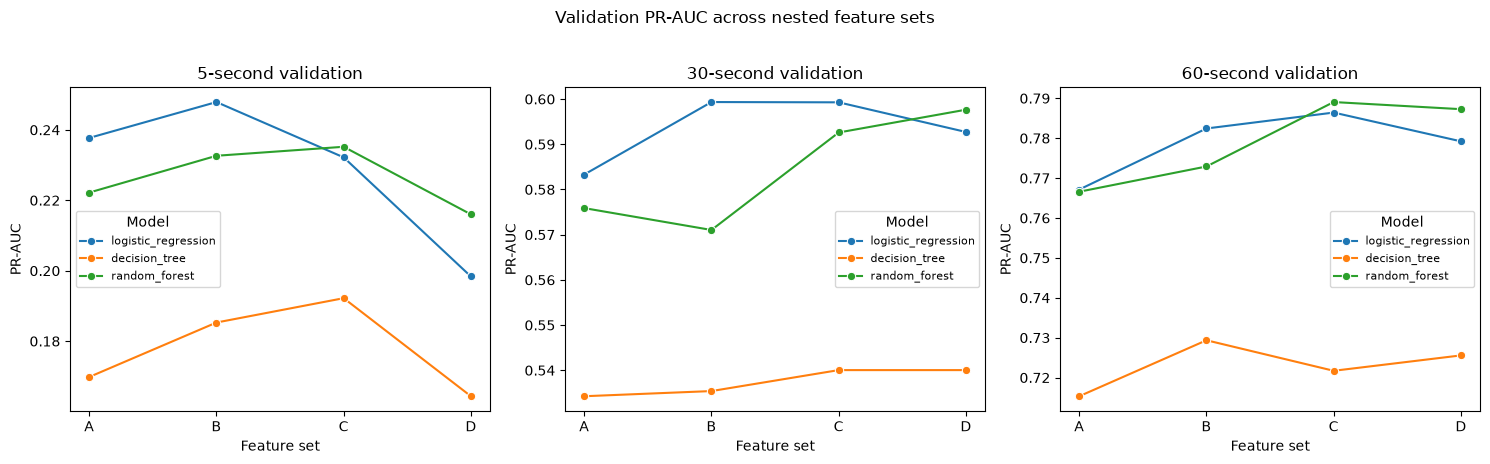

In [11]:
plot_data = validation_results.loc[
    validation_results["feature_set"].isin(FEATURE_SETS)
].copy()
plot_data["feature_set"] = pd.Categorical(
    plot_data["feature_set"],
    categories=list(FEATURE_SETS),
    ordered=True,
)
plot_data["feature_set_short"] = plot_data["feature_set"].map({
    "A_order": "A",
    "B_order_lob": "B",
    "C_order_lob_flow": "C",
    "D_full_history": "D",
})

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=False)
for ax, horizon in zip(axes, HORIZONS):
    horizon_data = plot_data.loc[plot_data["horizon_seconds"].eq(horizon)]
    sns.lineplot(
        data=horizon_data,
        x="feature_set_short",
        y="pr_auc",
        hue="model",
        marker="o",
        ax=ax,
    )
    ax.set_title(f"{horizon}-second validation")
    ax.set_xlabel("Feature set")
    ax.set_ylabel("PR-AUC")
    ax.legend(title="Model", fontsize=8)

fig.suptitle("Validation PR-AUC across nested feature sets", y=1.02)
fig.tight_layout()
plt.show()

In [12]:
candidate_results = validation_results.loc[
    validation_results["feature_set"].ne("baseline")
].copy()

best_by_horizon = (
    candidate_results
    .sort_values(
        ["horizon_seconds", "pr_auc", "brier_score"],
        ascending=[True, False, True],
    )
    .groupby("horizon_seconds", as_index=False)
    .first()
)

best_by_horizon[
    ["horizon_seconds", "feature_set", "model", "roc_auc", "pr_auc", "brier_score"]
].round(4)

,horizon_seconds,feature_set,model,roc_auc,pr_auc,brier_score
0,5,B_order_lob,logistic_regression,0.6645,0.2479,0.0873
1,30,B_order_lob,logistic_regression,0.6744,0.5993,0.2179
2,60,C_order_lob_flow,random_forest,0.6812,0.7891,0.2164


In [13]:
print("History ablation summary (positive values favor set D):")
for row in history_delta.itertuples(index=False):
    print(
        f"{row.horizon_seconds:>2}s | {row.model:<19} | "
        f"ΔPR-AUC={row.delta_pr_auc_D_minus_C:+.4f} | "
        f"ΔROC-AUC={row.delta_roc_auc_D_minus_C:+.4f} | "
        f"Brier improvement={row.brier_improvement_C_minus_D:+.4f}"
    )

History ablation summary (positive values favor set D):
 5s | logistic_regression | ΔPR-AUC=-0.0338 | ΔROC-AUC=-0.0194 | Brier improvement=-0.0016
 5s | decision_tree       | ΔPR-AUC=-0.0278 | ΔROC-AUC=-0.0262 | Brier improvement=-0.0016
 5s | random_forest       | ΔPR-AUC=-0.0192 | ΔROC-AUC=-0.0177 | Brier improvement=+0.0004
30s | logistic_regression | ΔPR-AUC=-0.0066 | ΔROC-AUC=-0.0073 | Brier improvement=-0.0019
30s | decision_tree       | ΔPR-AUC=+0.0000 | ΔROC-AUC=+0.0000 | Brier improvement=+0.0000
30s | random_forest       | ΔPR-AUC=+0.0050 | ΔROC-AUC=+0.0062 | Brier improvement=-0.0005
60s | logistic_regression | ΔPR-AUC=-0.0072 | ΔROC-AUC=-0.0079 | Brier improvement=-0.0017
60s | decision_tree       | ΔPR-AUC=+0.0039 | ΔROC-AUC=+0.0008 | Brier improvement=+0.0005
60s | random_forest       | ΔPR-AUC=-0.0018 | ΔROC-AUC=+0.0030 | Brier improvement=-0.0007


## Next checkpoint

Use these validation results to select a small number of candidate model/feature-set combinations. The next notebook should tune only those candidates, compare probability-calibration methods, and choose classification thresholds using validation data. The test split must remain sealed until those choices are fixed.

The 0.5-threshold metrics in this notebook are descriptive and must not be treated as the final operating point.